# Reddit activity and Dubai real estate registrations

Companion analysis for the exploratory weekly association study. This notebook uses the shared repository implementation, so the notebook and command-line results come from the same code.

The inputs are observed weekly aggregates. No raw Reddit text or DeBERTa inference is needed. See the repository README for findings and `docs/methods.md` for assumptions. Independent held-out human relevance validation remains pending.

## 1. Locate the repository and dependencies
Locally, install `requirements.txt` and open this notebook from the repository. In Colab, the setup cell clones the repository if necessary; the next cell installs the aggregate-analysis dependencies.

In [1]:
from pathlib import Path
import sys, subprocess

ROOT = Path.cwd()
if not (ROOT / "scripts/reproduce.py").exists() and (ROOT.parent / "scripts/reproduce.py").exists():
    ROOT = ROOT.parent
if not (ROOT / "scripts/reproduce.py").exists() and "google.colab" in sys.modules:
    ROOT = Path("/content/dld_reddit")
    if not ROOT.exists():
        subprocess.run(["git", "clone", "https://github.com/aaronab810/dld_reddit.git", str(ROOT)], check=True)
if not (ROOT / "scripts/reproduce.py").exists():
    raise FileNotFoundError("Open this notebook from a clone of aaronab810/dld_reddit")
sys.path.insert(0, str(ROOT / "src"))


In [2]:
if "google.colab" in sys.modules:
    subprocess.run([sys.executable, "-m", "pip", "install", "-r", str(ROOT / "requirements.txt")], check=True)
import pandas as pd
from IPython.display import display, Image


## 2. Inspect the observed inputs
There are 58 observed Monday–Sunday bins in Asia/Dubai. Completeness of the edge weeks is uncertain; the reproduction includes a 56-interior-bin sensitivity.

In [3]:
weekly = pd.read_csv(ROOT / "data/weekly_counts.csv", parse_dates=["week"])
display(pd.read_csv(ROOT / "data/variables.csv"))
print(f"Observed bins: {len(weekly)}; labels: {weekly.week.min().date()} to {weekly.week.max().date()}")
display(weekly.head())


Observed bins: 58; labels: 2025-07-28 to 2026-08-31


,variable,label,definition,role,aggregation
0,reddit_total,Reddit total activity,All retained posts + comments in both subreddits,Primary,"Weekly count; Monday–Sunday, Dubai local time"
1,reddit_posts,Reddit posts,Retained top-level submissions (post_type = re...,Primary,"Weekly count; Monday–Sunday, Dubai local time"
2,reddit_comments,Reddit comments,Retained comments (post_type = reddit_comment),Secondary,"Weekly count; Monday–Sunday, Dubai local time"
3,reddit_dubai,r/dubai activity,All retained posts + comments in r/dubai,Primary,"Weekly count; Monday–Sunday, Dubai local time"
4,reddit_dubairealestate,r/DubaiRealEstate activity,All retained posts + comments in r/dubaireales...,Primary,"Weekly count; Monday–Sunday, Dubai local time"
5,dld_total,Total DLD transactions,"Unique transaction IDs across Sales, Mortgages...",Primary,"Weekly count; Monday–Sunday, Dubai local time"
6,dld_sales,DLD sales,Unique transaction IDs with trans_group_en = S...,Primary,"Weekly count; Monday–Sunday, Dubai local time"
7,dld_mortgages,DLD mortgages,Unique transaction IDs with trans_group_en = M...,Primary,"Weekly count; Monday–Sunday, Dubai local time"
8,dld_gifts,DLD gifts,Unique transaction IDs with trans_group_en = G...,Primary,"Weekly count; Monday–Sunday, Dubai local time"
9,dld_offplan_sales,Off-plan sales,Sales AND reg_type_en = Off-Plan Properties (r...,Secondary,"Weekly count; Monday–Sunday, Dubai local time"


,week,reddit_total,reddit_posts,reddit_comments,reddit_dubai,reddit_dubairealestate,dld_total,dld_sales,dld_mortgages,dld_gifts,dld_offplan_sales,dld_ready_sales
0,2025-07-28,2527,277,2250,807,1720,5184,4147.0,907.0,130.0,2756,1391
1,2025-08-04,2340,290,2050,712,1628,5199,4139.0,918.0,142.0,2693,1446
2,2025-08-11,2350,273,2077,868,1482,5680,4677.0,790.0,213.0,3408,1269
3,2025-08-18,2797,285,2512,596,2201,5619,4632.0,804.0,183.0,3404,1228
4,2025-08-25,3178,327,2851,795,2383,5386,4319.0,871.0,196.0,3005,1314


## 3. Reproduce and verify
This executes the level/change correlations, calendar-time adjustment, lag profiles, historical aggregate comparison and paired stationary bootstrap. All 21 reference tables must match, or the run fails. Bootstrap settings are 10,000 replicates and expected block lengths of 2, 4 and 8 weeks.

In [4]:
import runpy
reproduce = runpy.run_path(str(ROOT / "scripts/reproduce.py"))["reproduce"]
OUT = reproduce(ROOT)


Reproduction complete: 21 reference tables verified. Outputs: outputs/


## 4. Read the results
Compare transformations and the full lag profiles. Positive lag means Reddit precedes DLD. A boundary extremum is not an established response delay; bootstrap intervals are exploratory and pointwise.

,reddit,dld,levels_pearson,levels_n,levels_spearman,differences_pearson,differences_n,differences_spearman
1,reddit_total,dld_sales,-0.174826,58,-0.166603,0.258065,57,0.433537
7,reddit_posts,dld_sales,-0.182775,58,-0.255392,0.507892,57,0.437122
13,reddit_comments,dld_sales,-0.166573,58,-0.148212,0.213559,57,0.407292
19,reddit_dubai,dld_sales,0.571715,58,0.546397,0.300229,57,0.332977
25,reddit_dubairealestate,dld_sales,-0.308601,58,-0.404719,0.181134,57,0.326873


,coverage,reddit,dld,n,expected_block_length,replicates,valid_replicates,correlation,ci_low,ci_high
0,observed_58_weeks,reddit_total,dld_sales,57,2,10000,10000,0.258065,-0.118317,0.591035
1,observed_58_weeks,reddit_posts,dld_sales,57,2,10000,10000,0.507892,0.257823,0.693622
2,observed_58_weeks,reddit_dubai,dld_sales,57,2,10000,10000,0.300229,0.132286,0.472154
3,observed_58_weeks,reddit_dubairealestate,dld_sales,57,2,10000,10000,0.181134,-0.199742,0.516624
4,observed_58_weeks,reddit_total,dld_sales,57,4,10000,10000,0.258065,-0.108661,0.579633
5,observed_58_weeks,reddit_posts,dld_sales,57,4,10000,10000,0.507892,0.278296,0.676187
6,observed_58_weeks,reddit_dubai,dld_sales,57,4,10000,10000,0.300229,0.162606,0.457164
7,observed_58_weeks,reddit_dubairealestate,dld_sales,57,4,10000,10000,0.181134,-0.194781,0.512169
8,observed_58_weeks,reddit_total,dld_sales,57,8,10000,10000,0.258065,-0.077803,0.556767
9,observed_58_weeks,reddit_posts,dld_sales,57,8,10000,10000,0.507892,0.298259,0.651427


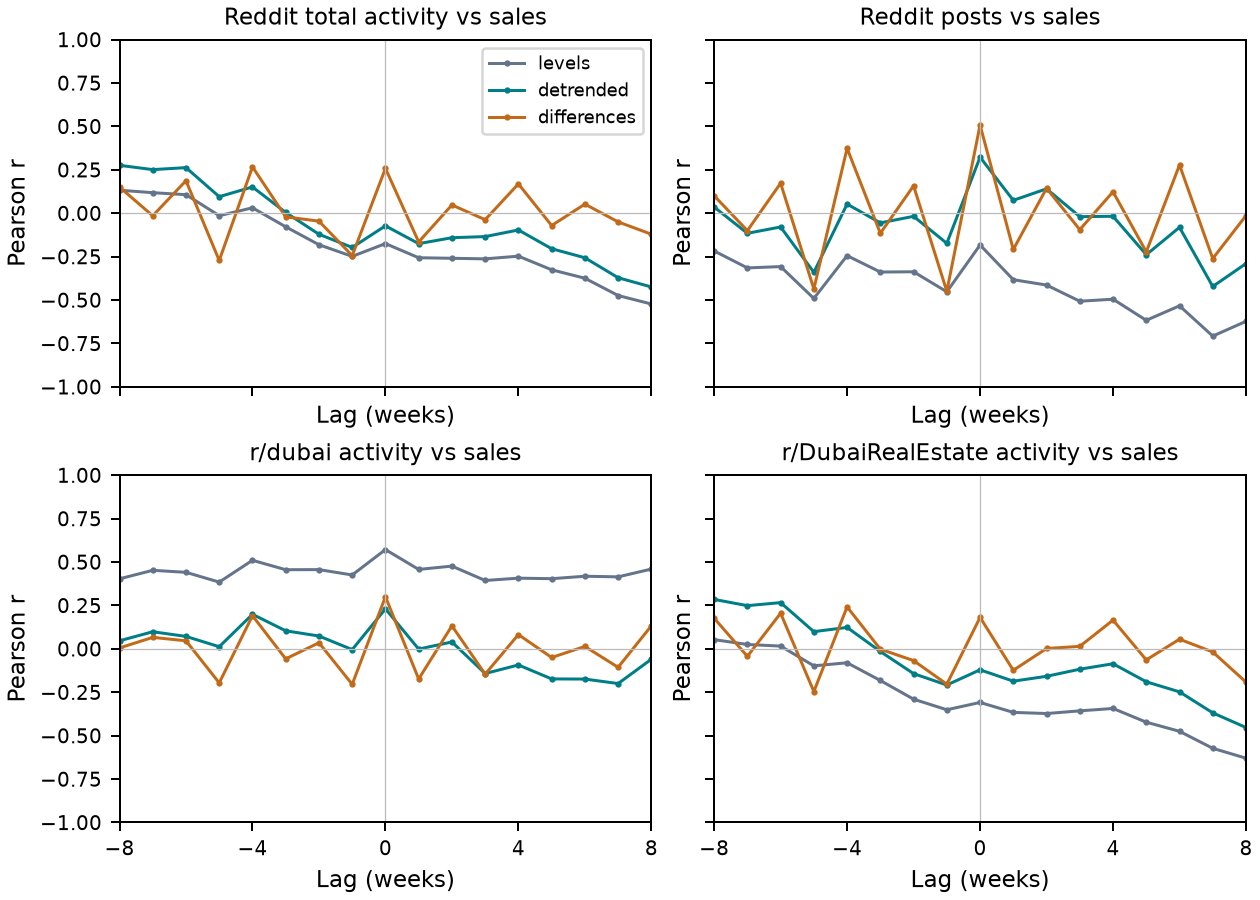

In [5]:
pairs = pd.read_csv(OUT / "sensitivity/levels_vs_changes_all_30_pairs.csv")
display(pairs.loc[pairs.dld.eq("dld_sales")])
display(pd.read_csv(OUT / "bootstrap/stationary_bootstrap_changes.csv"))
display(Image(filename=str(OUT / "sensitivity/lag_profiles_minus8_plus8.png")))


## 5. Interpretation
The study finds measure-specific associations and no robust single lead–lag delay across transformations and temporal support. It does not establish impact, speculative purchasing, causation or validated forecasting signals.

The historical comparison reproduces archived aggregate coefficients, not raw records. Upstream DeBERTa extraction is documented separately in `deberta_extraction.ipynb`; the full extended-corpus assembly and independent relevance validation are not reproduced here.